# U3 Saber Hacer: análisis supervisado (COVID Tracking Project)

Notebook del proceso. Usa las funciones de `src/u3_supervised_analysis.py` para que el notebook y el script den los mismos resultados.

**Pregunta:** con los datos que un estado reporta hoy, ¿se puede anticipar su carga hospitalaria de los próximos 7 días?

- Regresión: cambio % de hospitalizados (promedio de 7 días) dentro de 7 días.
- Clasificación: alerta si ese cambio es mayor a +5 %.

In [1]:
import sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import u3_supervised_analysis as A
pd.set_option('display.precision', 3)

## 1. Dataset original y limpieza

In [2]:
raw = pd.read_csv(A.RAW_FILE)
print('Dataset original:', raw.shape)
clean = A.load_and_clean(A.RAW_FILE)
print('Dataset limpio:', clean.shape)
clean.head()

Dataset original: (20780, 41)
Dataset limpio: (18995, 10)


,date,state,new_deaths,hospitalized,new_cases,new_tests,new_cases_7d,new_deaths_7d,new_tests_7d,hospitalized_7d
0,2020-03-06,AK,0,NaN,0,0,NaN,NaN,NaN,NaN
1,2020-03-07,AK,0,NaN,0,4,NaN,NaN,NaN,NaN
2,2020-03-08,AK,0,NaN,0,2,NaN,NaN,NaN,NaN
3,2020-03-09,AK,0,NaN,0,9,NaN,NaN,NaN,NaN
4,2020-03-10,AK,0,NaN,0,0,NaN,NaN,NaN,NaN


## 2. Variables de entrada y variables objetivo

In [3]:
dataset = A.build_model_dataset(clean).sort_values(['date', 'state']).reset_index(drop=True)
print(dataset['split'].value_counts())
dataset[A.FEATURES + ['target_change_pct', 'target_alert']].describe().T

split
train    8426
test     6079
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
hosp_growth_3d,14499.0,0.570,12.412,-64.651,-6.525,-0.417,6.244,200.000
hosp_growth_7d,14505.0,1.681,17.231,-50.671,-10.679,-0.609,11.497,130.645
hosp_growth_prev_7d,14294.0,3.089,20.290,-46.420,-9.952,0.221,12.496,571.137
cases_growth_3d,14505.0,1.765,15.080,-62.311,-7.353,0.647,9.400,287.473
cases_growth_7d,14505.0,5.301,29.057,-70.142,-14.380,1.673,20.049,366.756
cases_growth_prev_7d,14505.0,6.228,29.798,-70.142,-14.108,2.501,21.467,366.756
positivity_7d,14483.0,8.914,8.351,0.259,3.730,6.545,11.417,100.000
cases_per_hosp,14505.0,1.552,0.871,0.122,0.948,1.436,1.971,6.637
deaths_per_100_hosp,14505.0,2.551,1.707,0.000,1.545,2.213,3.125,39.604
target_change_pct,14505.0,0.736,16.592,-46.420,-11.453,-1.278,10.674,130.645


## 3. División temporal y validación cruzada

In [4]:
train = dataset[dataset['split'] == 'train'].reset_index(drop=True)
test = dataset[dataset['split'] == 'test'].reset_index(drop=True)
folds = A.temporal_folds(train['date'])
for i, (tr, va) in enumerate(folds, 1):
    print(f'Fold {i}: entrena {len(tr):>5} filas | valida {train.date[va].min().date()} a {train.date[va].max().date()}')

Fold 1: entrena   838 filas | valida 2020-05-18 a 2020-06-18
Fold 2: entrena  2170 filas | valida 2020-06-19 a 2020-07-20
Fold 3: entrena  3574 filas | valida 2020-07-21 a 2020-08-21
Fold 4: entrena  5067 filas | valida 2020-08-22 a 2020-09-22
Fold 5: entrena  6571 filas | valida 2020-09-23 a 2020-10-24


## 4. Entrenamiento, optimización y comparación: regresión

In [5]:
reg = A.run_regression(dataset, train, test, folds)
reg.comparison

[regression] Regresión lineal (Ridge): CV MAE 7.670 -> 7.668


[regression] Random Forest: CV MAE 8.520 -> 7.996


[regression] Gradient Boosting: CV MAE 9.121 -> 8.038


,model,cv_MAE_default,cv_MAE,best_params,n_candidates,test_MAE,test_RMSE,test_R2
0,Línea base (tendencia),9.588,9.588,-,0,7.372,10.405,0.606
1,Regresión lineal (Ridge),7.670,7.668,{'alpha': 100.0},5,6.758,9.041,0.702
2,Random Forest,8.520,7.996,"{'max_depth': 16, 'max_features': 0.5, 'min_sa...",18,6.443,8.581,0.732
3,Gradient Boosting,9.121,8.038,"{'l2_regularization': 0.0, 'learning_rate': 0....",24,6.950,9.053,0.702


## 5. Entrenamiento, optimización y comparación: clasificación

In [6]:
clf = A.run_classification(dataset, train, test, folds)
clf.comparison

[classification] Regresión logística: CV F1 0.698 -> 0.717


[classification] Random Forest: CV F1 0.669 -> 0.692


[classification] Gradient Boosting: CV F1 0.605 -> 0.680


,model,cv_F1_default,cv_F1,best_params,n_candidates,test_Accuracy,test_Precision,test_Recall,test_F1,test_ROC_AUC
0,Línea base (tendencia),0.616,0.616,-,0,0.869,0.771,0.871,0.818,0.937
1,Regresión logística,0.698,0.717,{'C': 0.001},5,0.870,0.765,0.891,0.823,0.945
2,Random Forest,0.669,0.692,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",18,0.878,0.771,0.913,0.836,0.957
3,Gradient Boosting,0.605,0.680,"{'l2_regularization': 0.0, 'learning_rate': 0....",24,0.874,0.764,0.912,0.831,0.955


## 6. Gráficas de desempeño

{'patients_MAE_model': 97.06069581283388, 'patients_MAE_baseline': 102.16569534413351, 'national_peak_date': '2021-01-12', 'national_peak_real': 130709.85714285714, 'national_peak_pred': 132272.1505811105}
[[3454, 563], [225, 1837]]


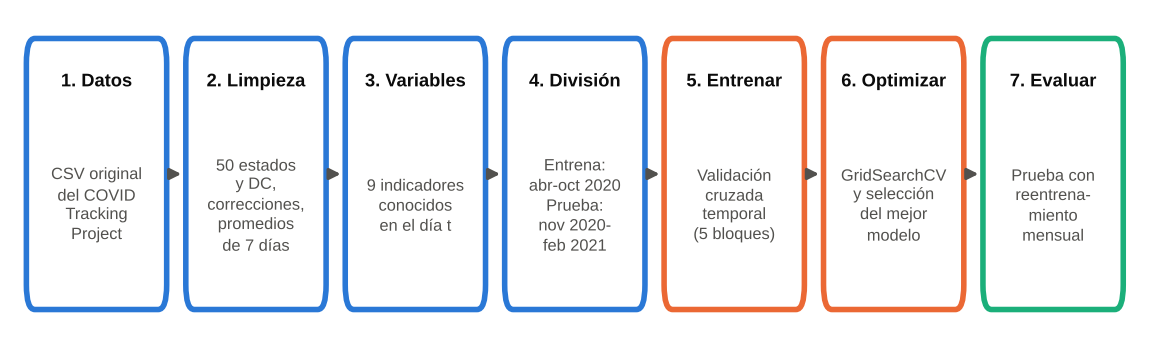

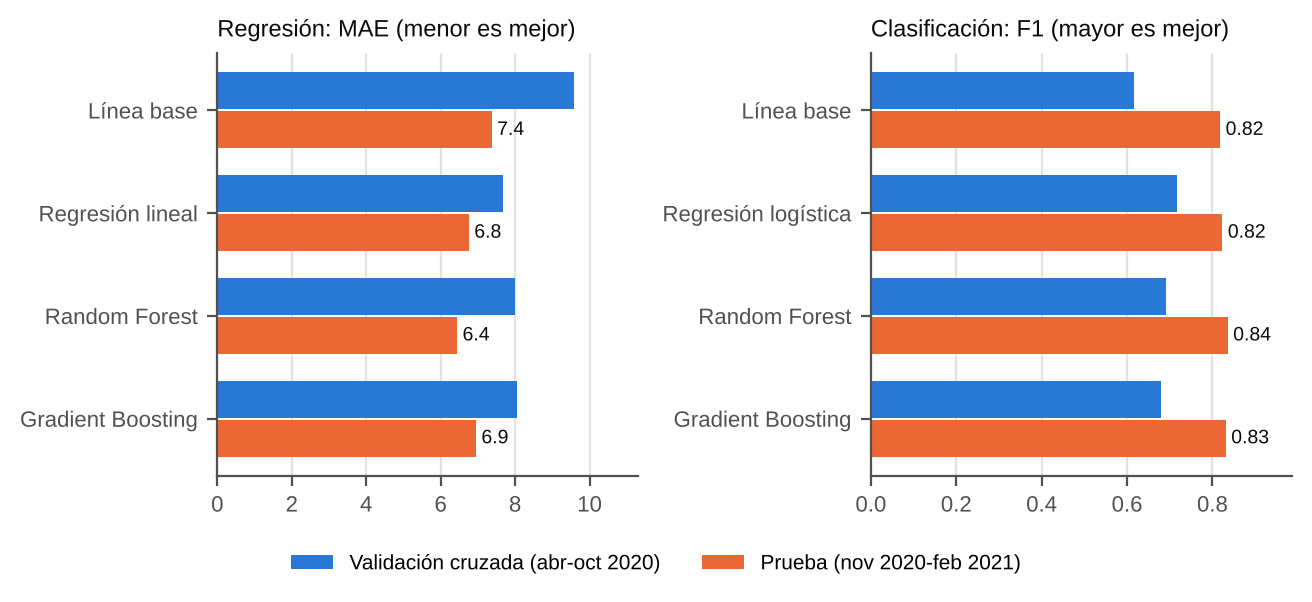

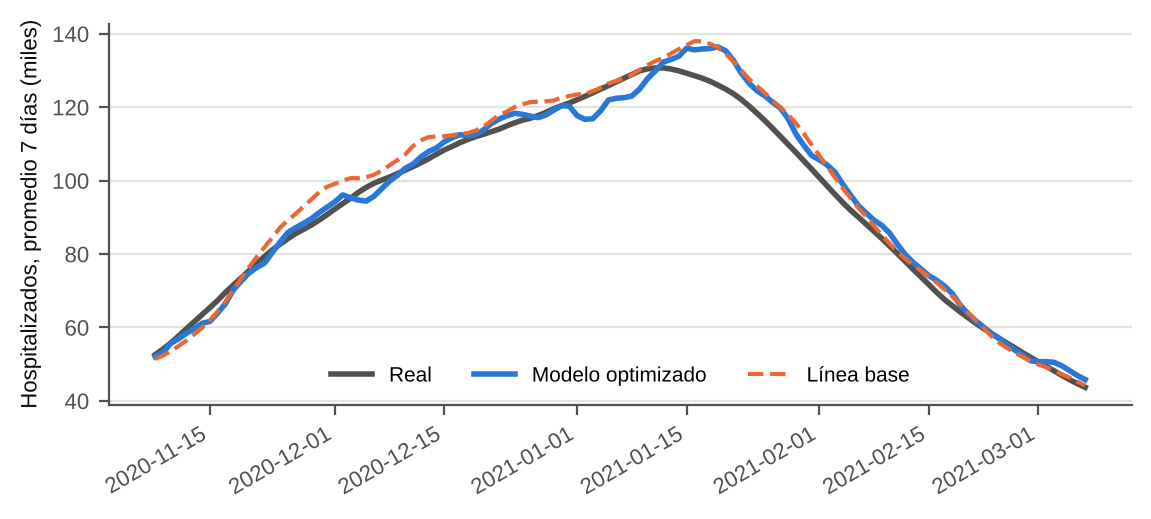

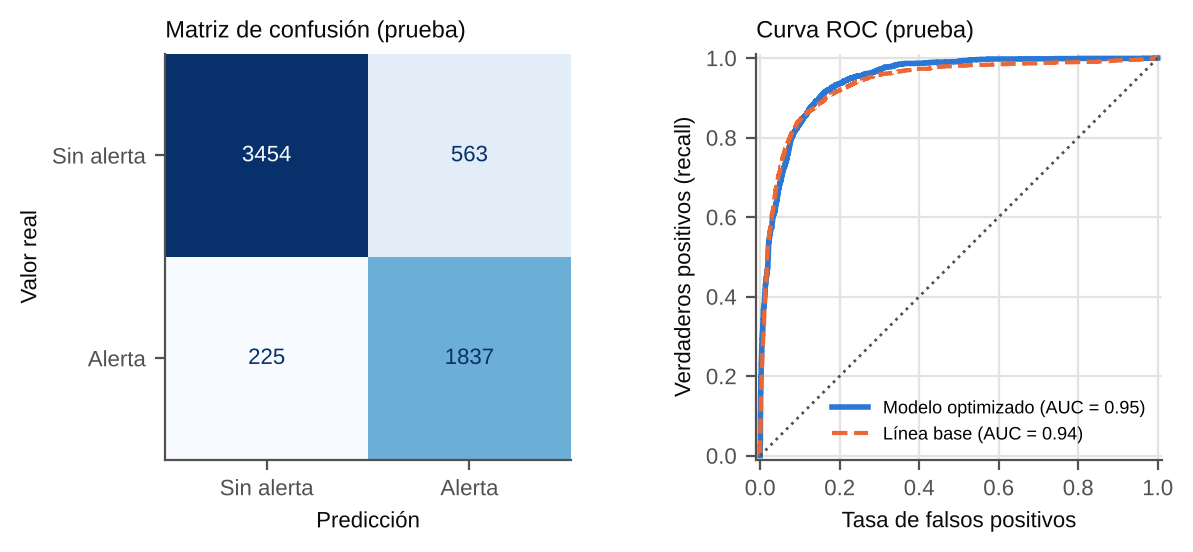

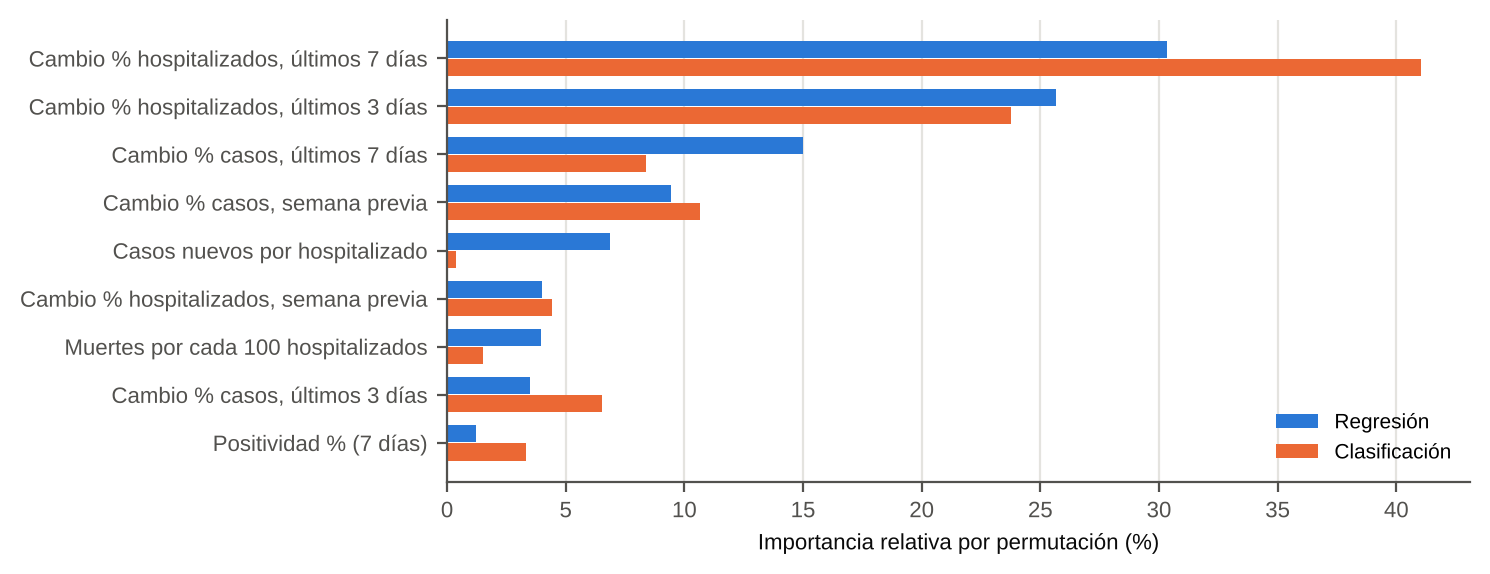

In [7]:
from IPython.display import Image, display
for d in (A.FIG_DIR, A.TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)
A.figure_workflow()
A.figure_comparison(reg.comparison, clf.comparison)
print(A.figure_national_forecast(test, reg.test_pred))
print(A.figure_classifier(test['target_alert'], clf.test_pred, clf.test_score, A.baseline_classification(test[A.FEATURES])[1]))
A.figure_importance(reg.tuned_model, clf.tuned_model, test[A.FEATURES], test['target_change_pct'], test['target_alert'])
for f in sorted(A.FIG_DIR.glob('fig*.png')):
    display(Image(filename=str(f)))